In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [5]:
def translate(p, dx, dy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, dx],
                  [0.0, 1.0, dy],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                  [np.sin(theta),  np.cos(theta), 0.0],
                  [0.0,            0.0,           1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[sx,  0.0, 0.0],
                  [0.0, sy,  0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, sx,  0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0],
                  [sy,  1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0],
                  [ 0.0, 1.0, 0.0],
                  [ 0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0,  0.0, 0.0],
                  [ 0.0, -1.0, 0.0],
                  [ 0.0,  0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def reflect_yx(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[0.0, 1.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

In [6]:
def apply(points, func, *args):
    result = []
    for p in points:
        result.append(func(p, *args))
    return result


def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')


def draw_rectangle(ax, p1, p2, p3, p4):
    my_polygon = Polygon([p1, p2, p3, p4])
    ax.add_patch(my_polygon)


def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])
    draw_cockpit(ax, p1, p2, p3, p4)
    draw_left_arm(ax, p1, p2, p3, p4)
    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)


def draw_cockpit(ax, p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply(q, translate, -LEN / 2, -LEN / 2)
    q = apply(q, scale, 5, 5)
    q = apply(q, rotate, np.pi / 4)
    draw_rectangle(ax, *q)


def left_arm(p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply(q, scale, 6.5, 0.8)
    q = apply(q, shear_y, -0.13)
    q = apply(q, translate, 150, 43)
    return q


def draw_left_arm(ax, p1, p2, p3, p4):
    arm = left_arm(p1, p2, p3, p4)
    draw_rectangle(ax, *arm)
    draw_rectangle(ax, *apply(arm, reflect_x))


def draw_right_arm(ax, p1, p2, p3, p4):
    arm = left_arm(p1, p2, p3, p4)
    draw_rectangle(ax, *apply(arm, reflect_y))
    draw_rectangle(ax, *apply(arm, reflect_origin))


def left_wing(p1, p2, p3, p4):
    middle = [p1, p2, p3, p4]
    middle = apply(middle, scale, 1, 8)
    middle = apply(middle, translate, 750, -400)

    tip = [p1, p2, p3, p4]
    tip = apply(tip, scale, 1, 2)
    tip = apply(tip, shear_y, 2)
    tip = apply(tip, translate, 750, 200)
    return middle, tip


def draw_left_wing(ax, p1, p2, p3, p4):
    middle, tip = left_wing(p1, p2, p3, p4)
    draw_rectangle(ax, *middle)
    draw_rectangle(ax, *tip)
    draw_rectangle(ax, *apply(tip, reflect_x))


def draw_right_wing(ax, p1, p2, p3, p4):
    middle, tip = left_wing(p1, p2, p3, p4)
    draw_rectangle(ax, *apply(middle, reflect_y))
    draw_rectangle(ax, *apply(tip, reflect_y))
    draw_rectangle(ax, *apply(tip, reflect_origin))

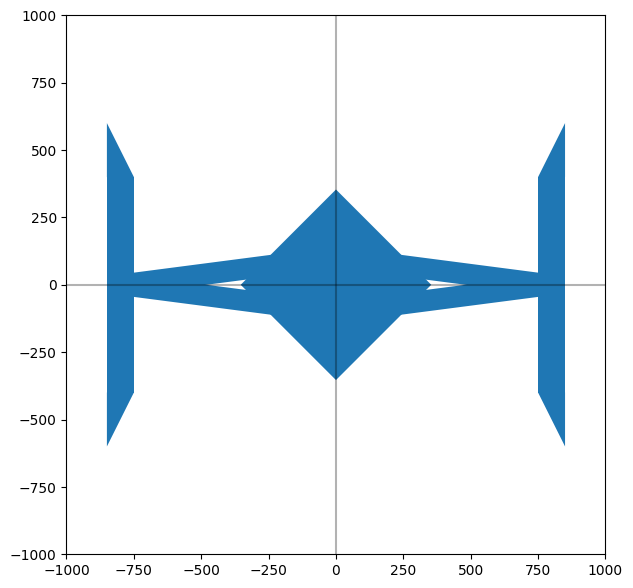

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()